In [20]:
from src.db_manager import ConexaoBanco
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from src.features.preparar_dados import carregar_treino_teste
import pandas as pd

In [3]:
db = ConexaoBanco()
df = db.obter_dataframe("SELECT * FROM tb_abt_tuberculose")

[*] Conexão estabelecida com o banco 'casos_tuberculose' usando mysql+pymysql.


In [4]:
categoricas = ["faixa_etaria", "sexo", "teste_hiv", "alcool", "tabagismo",
            "drogas", "escolaridade", "raca", "faixa_populacao", "regiao"]
numericas = ["idhm", "indice_gini", "cobertura_aps_2021"]

#fazer o one hot encoding
X = pd.get_dummies(df[categoricas + numericas], columns=categoricas,
                drop_first=True, dtype=int)

print(X.columns.tolist())

['idhm', 'indice_gini', 'cobertura_aps_2021', 'faixa_etaria_30 - 39 anos', 'faixa_etaria_40 - 49 anos', 'faixa_etaria_50 - 59 anos', 'faixa_etaria_Acima de 60 anos', 'faixa_etaria_Ignorado', 'sexo_Ignorado', 'sexo_Masculino', 'teste_hiv_Ignorado', 'teste_hiv_Negativo', 'teste_hiv_Não realizado', 'teste_hiv_Positivo', 'alcool_Não', 'alcool_Sim', 'tabagismo_Não', 'tabagismo_Sim', 'drogas_Não', 'drogas_Sim', 'escolaridade_Até fundamental', 'escolaridade_Ensino médio', 'escolaridade_Ensino superior', 'escolaridade_Ignorado', 'raca_Branca', 'raca_Ignorado', 'raca_Parda', 'raca_Preta', 'faixa_populacao_2 - 5001 até 10000', 'faixa_populacao_3 - 10001 até 20000', 'faixa_populacao_4 - 20001 até 50000', 'faixa_populacao_5 - 50001 até 100000', 'faixa_populacao_6 - 100001 até 500000', 'faixa_populacao_7 - Maior que 500000', 'regiao_2 - Nordeste', 'regiao_3 - Sudeste', 'regiao_4 - Sul', 'regiao_5 - Centro-Oeste']


In [5]:
y = df["alvo_preditivo"]

print(y)

0         1
1         1
2         1
3         1
4         1
         ..
185356    0
185357    0
185358    0
185359    0
185360    0
Name: alvo_preditivo, Length: 185361, dtype: int64


In [21]:
X_train, X_test, y_train, y_test = carregar_treino_teste()



[*] Conexão estabelecida com o banco 'casos_tuberculose' usando mysql+pymysql.
Treino: 40982 casos {0: 20491, 1: 20491} (balanceado)
Teste:  55609 casos {0: 46827, 1: 8782} (proporção real)
Variáveis: 38 colunas


In [9]:
scaler = StandardScaler()
X_train[numericas] = scaler.fit_transform(X_train[numericas])
X_test[numericas] = scaler.transform(X_test[numericas])

In [14]:
# junta X e y do treino para remover linhas inteiras
treino = X_train.copy()
treino["alvo_preditivo"] = y_train

abandono = treino[treino["alvo_preditivo"] == 1]
cura = treino[treino["alvo_preditivo"] == 0]

# sorteia, entre as curas, a mesma quantidade de casos de abandono
cura_amostra = cura.sample(n=len(abandono), random_state=42)

# junta e embaralha
treino_bal = pd.concat([abandono, cura_amostra]).sample(frac=1, random_state=42)

X_train_bal = treino_bal.drop(columns="alvo_preditivo")
y_train_bal = treino_bal["alvo_preditivo"]

X_train = X_train_bal
y_train = y_train_bal

print("Antes: ", y_train.value_counts().to_dict())
print("Depois:", y_train_bal.value_counts().to_dict())

Antes:  {0: 20476, 1: 20476}
Depois: {0: 20476, 1: 20476}


In [22]:
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)

print("Acurácia do Classificador = %f" % acc)

Acurácia do Classificador = 0.669460


,variavel,coeficiente,odds_ratio
29,faixa_populacao_2 - 5001 até 10000,-0.664841,0.514355
30,faixa_populacao_3 - 10001 até 20000,-0.534052,0.586225
31,faixa_populacao_4 - 20001 até 50000,-0.494416,0.609927
28,faixa_populacao_1 - Até 5000,-0.369099,0.691357
32,faixa_populacao_5 - 50001 até 100000,-0.319458,0.726543
33,faixa_populacao_6 - 100001 até 500000,-0.283246,0.753335
2,cobertura_aps_2021,-0.066500,0.935663
14,alcool_Ignorado,-0.032883,0.967651
1,indice_gini,-0.023062,0.977202
35,regiao_2 - Nordeste,0.001957,1.001959


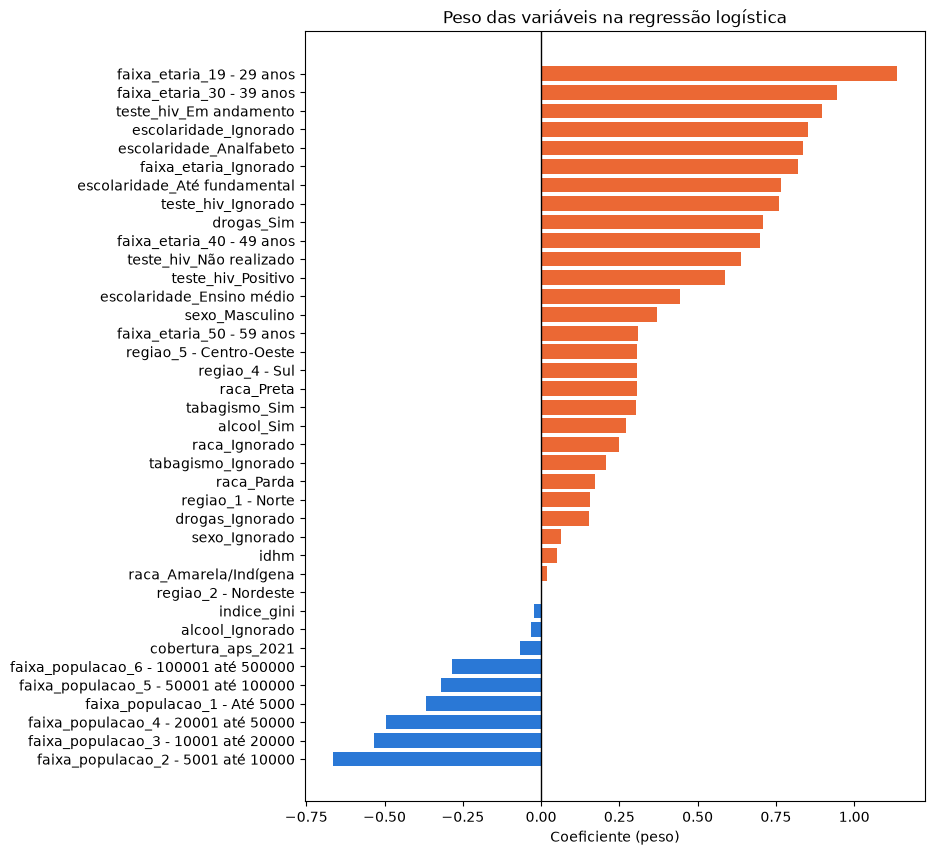

In [23]:
import numpy as np
import matplotlib.pyplot as plt

pesos = pd.DataFrame({
    "variavel": X_train.columns,
    "coeficiente": model.coef_[0],
})
pesos["odds_ratio"] = np.exp(pesos["coeficiente"])   # mais fácil de interpretar
pesos = pesos.sort_values("coeficiente")

display(pesos)

# gráfico: à direita do zero aumenta a chance de abandono; à esquerda, diminui
plt.figure(figsize=(8, 10))
plt.barh(pesos["variavel"], pesos["coeficiente"],
         color=["#eb6834" if c > 0 else "#2a78d6" for c in pesos["coeficiente"]])
plt.axvline(0, color="black", lw=1)
plt.xlabel("Coeficiente (peso)")
plt.title("Peso das variáveis na regressão logística")
plt.show()

In [24]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print(classification_report(y_test, y_pred, target_names=["Cura", "Abandono"]))
print("AUC:", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

        Cura       0.91      0.67      0.77     46827
    Abandono       0.27      0.65      0.38      8782

    accuracy                           0.67     55609
   macro avg       0.59      0.66      0.58     55609
weighted avg       0.81      0.67      0.71     55609

AUC: 0.712359792417719


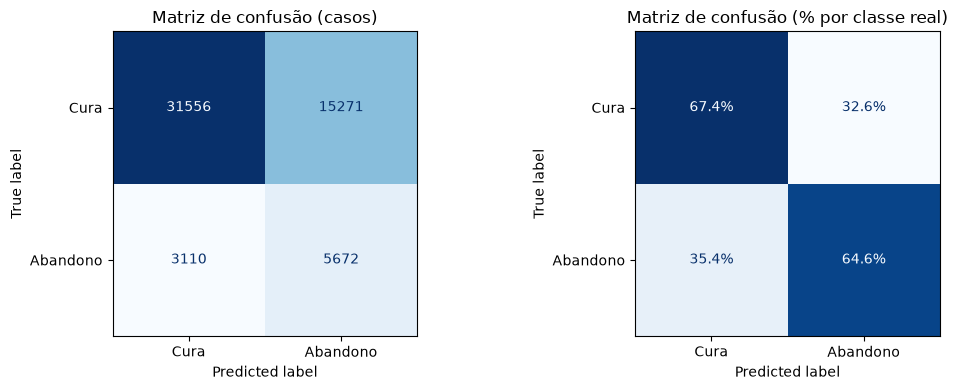

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# em número de casos
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Cura", "Abandono"],
    cmap="Blues", colorbar=False, ax=ax1)
ax1.set_title("Matriz de confusão (casos)")

# em proporção de cada classe real (cada linha soma 100%)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Cura", "Abandono"],
    normalize="true", values_format=".1%",
    cmap="Blues", colorbar=False, ax=ax2)
ax2.set_title("Matriz de confusão (% por classe real)")

plt.tight_layout()
plt.show()

In [26]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score
from src.features.preparar_dados import carregar_treino_teste, balancear

# treino SEM balancear: o balanceamento é feito dentro de cada rodada
X_train, X_test, y_train, y_test = carregar_treino_teste(balancear_treino=False)

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aucs, recalls = [], []

for rodada, (idx_tr, idx_val) in enumerate(kfold.split(X_train, y_train), start=1):
    X_tr, y_tr = X_train.iloc[idx_tr], y_train.iloc[idx_tr]
    X_val, y_val = X_train.iloc[idx_val], y_train.iloc[idx_val]   # proporção real

    X_tr, y_tr = balancear(X_tr, y_tr)                            # só a parte de treino

    model = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
    prob = model.predict_proba(X_val)[:, 1]
    aucs.append(roc_auc_score(y_val, prob))
    recalls.append(recall_score(y_val, prob >= 0.5))
    print(f"Rodada {rodada}: AUC = {aucs[-1]:.3f} | sensibilidade = {recalls[-1]:.3f}")

print(f"\nAUC média: {np.mean(aucs):.3f} ± {np.std(aucs):.3f}")
print(f"Sensibilidade média: {np.mean(recalls):.3f} ± {np.std(recalls):.3f}")

[*] Conexão estabelecida com o banco 'casos_tuberculose' usando mysql+pymysql.
Treino: 129752 casos {0: 109261, 1: 20491}
Teste:  55609 casos {0: 46827, 1: 8782} (proporção real)
Variáveis: 38 colunas
Rodada 1: AUC = 0.702 | sensibilidade = 0.632
Rodada 2: AUC = 0.712 | sensibilidade = 0.638
Rodada 3: AUC = 0.707 | sensibilidade = 0.645
Rodada 4: AUC = 0.707 | sensibilidade = 0.646
Rodada 5: AUC = 0.709 | sensibilidade = 0.634

AUC média: 0.708 ± 0.003
Sensibilidade média: 0.639 ± 0.006
